# Simulation des alertes sans heures supplémentaires

Sur le test historique, on remplace uniquement la valeur source `OverTime = Yes` par `No` chez tous les salariés exposés. On mesure ensuite les changements d’alerte chez les salariés partis et initialement détectés, avec le même modèle et le même seuil.

## 1. Reconstituer la régression logistique finale

L’artefact historique `outputs/models/04_Logistique.joblib` conserve `Education` et `HourlyRate`. L’analyse finale (`src/final_analysis.py`) archive la configuration, le split et les métriques, sans sérialiser son pipeline ajusté. On réajuste donc le pipeline final avec les paramètres et les exclusions archivés, sur les seules lignes d’entraînement et dans leur ordre d’origine. Le seuil provient de la ligne « Max OOF F2 » de la validation finale et est vérifié dans l’archive du test.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

racine = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/modeling.py').is_file())
sys.path.insert(0, str(racine))

from src.final_analysis import metrics
from src.modeling import build_pipelines, load_model_data, make_split

archives = racine / 'reports/tables/final'
config = json.loads((archives / 'model.json').read_text(encoding='utf-8'))
assert config['model'] == 'Logistique' and config['variant'] == 'pruned'
validation = pd.read_csv(archives / 'validation.csv', float_precision='round_trip')
reference = pd.read_csv(archives / 'test.csv', float_precision='round_trip').set_index('rule')
ligne_seuil = validation.loc[
    validation.model.eq(config['model'])
    & validation.variant.eq(config['variant'])
    & validation.rule.eq('Max OOF F2')
]
assert len(ligne_seuil) == 1
seuil = float(ligne_seuil.threshold.iloc[0])
assert seuil == reference.loc['Max OOF F2', 'threshold']

donnees, cible, lignes_source, _, quantitatives = load_model_data()
X_train, X_test, y_train, y_test, _, split = make_split(donnees, cible, lignes_source, n_splits=4)
split_archive = pd.read_csv(archives / 'split.csv', dtype={'pli_validation': 'Int64'})
pd.testing.assert_frame_equal(split, split_archive)
historique = pd.read_csv(racine / 'outputs/models/04_indices_split_plis.csv')
pd.testing.assert_frame_equal(split.drop(columns='pli_validation'), historique.drop(columns='pli_validation'))
assert (len(X_test), int(y_test.sum())) == (304, 50)
pd.testing.assert_index_equal(X_test.index, y_test.index)

pipeline = build_pipelines(quantitatives, excluded=config['candidate_exclusions'])[config['model']]
pipeline.set_params(**config['parameters']).fit(X_train, y_train)
classe_depart = int(np.flatnonzero(pipeline.classes_ == 1).item())
score_avant = pd.Series(pipeline.predict_proba(X_test)[:, classe_depart], index=X_test.index)
prediction_avant = score_avant >= seuil
rejoue = pd.DataFrame.from_dict(
    {regle: metrics(y_test, score_avant, ligne.threshold) for regle, ligne in reference.iterrows()},
    orient='index',
)
pd.testing.assert_frame_equal(rejoue, reference, check_names=False, atol=1e-12, rtol=0)
print(f'Seuil exact Max OOF F2 : {seuil!r}')
display(rejoue)

Seuil exact Max OOF F2 : 0.1524622157832296


,threshold,precision,recall,f2,ap,auc,tn,fp,fn,tp
Max OOF F2,0.152462,0.373832,0.80,0.651466,0.683905,0.86874,187,67,10,40
0.50,0.500000,0.800000,0.32,0.363636,0.683905,0.86874,250,4,34,16


## 2. Rejouer les scores sans heures supplémentaires

Le changement intervient avant l’encodage binaire du pipeline. Tous les salariés exposés sont concernés, y compris ceux qui sont restés. On vérifie que les autres entrées, la cible, l’ordre des lignes et les scores des salariés non exposés sont préservés.

In [2]:
exposes = X_test['OverTime'].eq('Yes')
cible_avant = y_test.copy(deep=True)
X_sans_heures_supp = X_test.copy(deep=True)
X_sans_heures_supp.loc[exposes, 'OverTime'] = 'No'

pd.testing.assert_index_equal(X_sans_heures_supp.index, y_test.index)
pd.testing.assert_series_equal(y_test, cible_avant)
pd.testing.assert_frame_equal(X_test.drop(columns='OverTime'), X_sans_heures_supp.drop(columns='OverTime'))
assert X_sans_heures_supp['OverTime'].eq('No').all()
assert X_test['OverTime'].eq('Yes').equals(exposes)

score_apres = pd.Series(pipeline.predict_proba(X_sans_heures_supp)[:, classe_depart], index=X_test.index)
prediction_apres = score_apres >= seuil
pd.testing.assert_series_equal(score_avant.loc[~exposes], score_apres.loc[~exposes], check_exact=True)
print('Alignement vérifié. Scores identiques pour les salariés non exposés.')

Alignement vérifié. Scores identiques pour les salariés non exposés.


## 3. Compter les départs initialement détectés qui changent de classe

Le dénominateur Y regroupe les départs observés chez les salariés exposés dont le score initial atteint le seuil. X compte ceux dont le nouveau score est strictement inférieur au seuil. La baisse moyenne de score est calculée sur l’ensemble des salariés exposés. X mesure des changements de classe prédite à seuil fixe. Le nombre de départs réellement évités reste à mesurer.

,Indicateur,Résultat
0,Salariés exposés dans le test,81
1,Départs observés parmi les exposés,28
2,Départs initialement détectés parmi les exposé...,27
3,Passent sous le seuil (X),11
4,Part qui passe sous le seuil (X/Y),40.7%
5,Restent en alerte (Y−X),16
6,Baisse moyenne du score chez les exposés,14.57 points de pourcentage


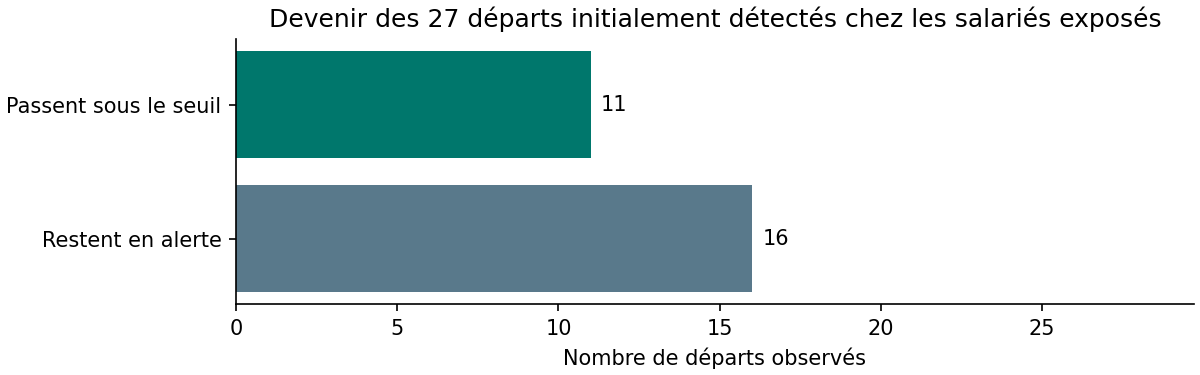

11 sur 27 départs observés et initialement détectés chez les salariés faisant des heures supplémentaires passent sous le seuil d’alerte dans le scénario sans heures supplémentaires.


In [3]:
departs_exposes = exposes & y_test.eq(1)
initialement_detectes = departs_exposes & prediction_avant
Y = int(initialement_detectes.sum())
X = int((initialement_detectes & ~prediction_apres).sum())
restent_en_alerte = int((initialement_detectes & prediction_apres).sum())
assert Y > 0 and X + restent_en_alerte == Y
baisse_moyenne_pp = 100 * (score_avant.loc[exposes] - score_apres.loc[exposes]).mean()

synthese = pd.DataFrame([
    ('Salariés exposés dans le test', int(exposes.sum())),
    ('Départs observés parmi les exposés', int(departs_exposes.sum())),
    ('Départs initialement détectés parmi les exposés (Y)', Y),
    ('Passent sous le seuil (X)', X),
    ('Part qui passe sous le seuil (X/Y)', f'{X / Y:.1%}'),
    ('Restent en alerte (Y−X)', restent_en_alerte),
    ('Baisse moyenne du score chez les exposés', f'{baisse_moyenne_pp:.2f} points de pourcentage'),
], columns=['Indicateur', 'Résultat'])
display(synthese)

fig, ax = plt.subplots(figsize=(8, 2.5), layout='constrained')
barres = ax.barh(['Passent sous le seuil', 'Restent en alerte'], [X, restent_en_alerte],
                 color=['#00776c', '#59798b'])
ax.bar_label(barres, padding=5)
ax.set(xlim=(0, Y + max(1, .1 * Y)), xlabel='Nombre de départs observés',
       title=f'Devenir des {Y} départs initialement détectés chez les salariés exposés')
ax.invert_yaxis()
ax.spines[['top', 'right']].set_visible(False)
from io import BytesIO
from IPython.display import Image

with BytesIO() as image:
    fig.savefig(image, format='png', dpi=150)
    display(Image(data=image.getvalue()))
plt.close(fig)

print(f'{X} sur {Y} départs observés et initialement détectés chez les salariés faisant des heures supplémentaires '
      'passent sous le seuil d’alerte dans le scénario sans heures supplémentaires.')